# LAB 09 — Bias, Variance and Imbalanced Data
# Name: Sneha Kanjwani
# Student ID: 023-24-0273
# Section: H
# GitHub: https://github.com/snehakanjwani30/Machine-Learning-Labs
# Kaggle: https://www.kaggle.com/snehakanjwani
# Dataset: Stroke Prediction Dataset (Kaggle)
# Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

# Part 0 — Setup and the Data

In [1]:
#Task 0.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    learning_curve,
    cross_val_predict
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42

np.random.seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
#Task 0.2
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nGender counts:")
display(df["gender"].value_counts(dropna=False))

print("\nStroke counts:")
display(df["stroke"].value_counts().sort_index())

print("\nStroke percentages:")
display(
    (df["stroke"].value_counts(normalize=True).sort_index() * 100)
    .round(2).to_frame("Percentage")
)

Dataset shape: (5110, 12)

First 5 rows:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



Missing values:


,Missing Values
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201



Gender counts:


gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


Stroke counts:


stroke
0    4861
1     249
Name: count, dtype: int64


Stroke percentages:


,Percentage
stroke,
0,95.13
1,4.87


In [3]:
#Task 0.3
df = df.drop(columns=["id"])

gender_counts = df["gender"].value_counts()
rare_genders = gender_counts[gender_counts < 10].index

print("Rare gender categories:", list(rare_genders))

df = df[~df["gender"].isin(rare_genders)].copy()

X = df.drop(columns=["stroke"])
y = df["stroke"].astype(int)

X = pd.get_dummies(X, drop_first=False, dtype=int)

print("\nCleaned dataset shape:", df.shape)
print("Encoded feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().sort_index())

Rare gender categories: ['Other']

Cleaned dataset shape: (5109, 11)
Encoded feature shape: (5109, 20)
Target shape: (5109,)

Target distribution:


stroke
0    4860
1     249
Name: count, dtype: int64

In [4]:
#Task 0.4
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_imputed),
    columns=X_train_imputed.columns,
    index=X_train_imputed.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_imputed),
    columns=X_test_imputed.columns,
    index=X_test_imputed.index
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nStroke cases in training set:", int(y_train.sum()))
print("Stroke cases in test set:", int(y_test.sum()))

print("\nMissing values after imputation:")
print("Training:", X_train_imputed.isnull().sum().sum())
print("Testing:", X_test_imputed.isnull().sum().sum())

print("\nScaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Training rows: 4087
Testing rows: 1022

Stroke cases in training set: 199
Stroke cases in test set: 50

Missing values after imputation:
Training: 0
Testing: 0

Scaled training shape: (4087, 20)
Scaled testing shape: (1022, 20)


In [5]:
#Task 0.5
print("Stroke cases in training set:", int(y_train.sum()))
print("Stroke cases in test set:", int(y_test.sum()))

Stroke cases in training set: 199
Stroke cases in test set: 50


Question
(a)In 2-3 lines: how imbalanced is the data? Why did we use stratify=y, and what could go wrong with only a 
few stroke cases in the test set?


Answer: The dataset is highly imbalanced because the number of patients without stroke is much greater than the number of patients with stroke. We used stratify=y to maintain approximately the same class proportions in the training and test sets. If the test set contains very few stroke cases, evaluation metrics such as recall may become unstable and may not reliably represent the model's performance.

# Part 1 — The Accuracy Trap

In [6]:
#Task 1.1
dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train_imputed, y_train)

dummy_predictions = dummy_model.predict(X_test_imputed)

baseline_accuracy = accuracy_score(y_test, dummy_predictions)

print("Baseline accuracy:", round(baseline_accuracy, 4))
print("Baseline accuracy (%):", round(baseline_accuracy * 100, 2))

Baseline accuracy: 0.9511
Baseline accuracy (%): 95.11


In [7]:
#Task 1.2
log_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

log_model.fit(X_train_scaled, y_train)

log_predictions = log_model.predict(X_test_scaled)
log_probabilities = log_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression trained successfully.")
print("Number of test predictions:", len(log_predictions))
print("First 10 predicted classes:", log_predictions[:10])
print("First 10 stroke probabilities:", log_probabilities[:10].round(4))

Logistic Regression trained successfully.
Number of test predictions: 1022
First 10 predicted classes: [0 0 0 0 0 0 0 0 0 0]
First 10 stroke probabilities: [0.0067 0.0013 0.03   0.0067 0.0414 0.029  0.0083 0.0949 0.0051 0.1359]


In [8]:
#Task 1.3
def evaluate_model(model, X_train_data, y_train_data,
                   X_test_data, y_test_data):

    model.fit(X_train_data, y_train_data)

    predictions = model.predict(X_test_data)
    probabilities = model.predict_proba(X_test_data)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test_data, predictions),
        "Precision": precision_score(
            y_test_data, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_data, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test_data, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(
            y_test_data, probabilities
        ),
        "PR AUC (Average Precision)": average_precision_score(
            y_test_data, probabilities
        )
    }

print("Evaluation function defined successfully.")

Evaluation function defined successfully.


In [9]:
#Task 1a
baseline_probabilities = dummy_model.predict_proba(X_test_imputed)[:, 1]

baseline_results = {
    "Accuracy": accuracy_score(y_test, dummy_predictions),
    "Precision": precision_score(
        y_test, dummy_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, dummy_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, dummy_predictions, zero_division=0
    ),
    "ROC AUC": roc_auc_score(y_test, baseline_probabilities),
    "PR AUC (Average Precision)": average_precision_score(
        y_test, baseline_probabilities
    )
}

log_results = evaluate_model(
    LogisticRegression(max_iter=1000, random_state=SEED),
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

comparison = pd.DataFrame({
    "Majority Baseline": baseline_results,
    "Logistic Regression": log_results
}).T

display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC (Average Precision)
Majority Baseline,0.9511,0.0,0.00,0.0000,0.5000,0.0489
Logistic Regression,0.9521,1.0,0.02,0.0392,0.8393,0.2696


Confusion matrix:
[[972   0]
 [ 49   1]]


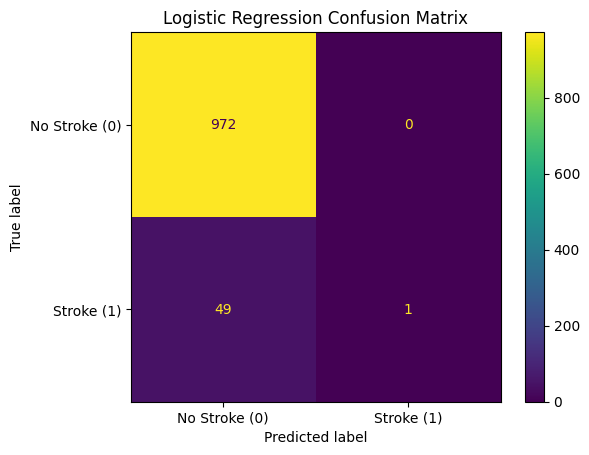

In [10]:
#Task 1b
cm = confusion_matrix(y_test, log_predictions)

print("Confusion matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Stroke (0)", "Stroke (1)"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()
#The false-negative count is particularly important in this medical screening task because it represents stroke cases the model failed to identify. 
#False positives also matter because they may lead to unnecessary follow-up assessments.

# QUESTIONS

(a) Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

Answer: The majority-class baseline can achieve high accuracy because most patients did not have a stroke, but it fails to identify the minority stroke class. Logistic Regression can learn patterns from patient features, so its precision, recall, F1-score, ROC AUC, and PR AUC should be compared with the baseline to assess its usefulness.


(b)Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and 
which numbers should we trust instead of accuracy?

Answer: A false negative occurs when a patient who belongs to the stroke class is incorrectly predicted as having no stroke. In medical screening, this can be serious because a patient who needs further assessment may be missed. Recall, precision, F1-score, ROC AUC, PR AUC, and the confusion matrix provide more useful information than accuracy alone.

# Part 2 — Underfitting, Overfitting, Bias and Variance

In [11]:
#Task 2.1.1
depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_auc_scores = []
cv_auc_scores = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=SEED
    )

    tree.fit(X_train_imputed, y_train)

    train_probabilities = tree.predict_proba(X_train_imputed)[:, 1]
    train_auc = roc_auc_score(y_train, train_probabilities)

    fold_scores = cross_val_score(
        DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED
        ),
        X_train_imputed,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    train_auc_scores.append(train_auc)
    cv_auc_scores.append(fold_scores.mean())

validation_results = pd.DataFrame({
    "Max Depth": [str(d) for d in depths],
    "Training ROC AUC": train_auc_scores,
    "CV ROC AUC": cv_auc_scores
})

display(validation_results.round(4))

best_index = np.argmax(cv_auc_scores)
best_depth = depths[best_index]

print("Best depth:", best_depth)
print("Best CV ROC AUC:", round(cv_auc_scores[best_index], 4))

,Max Depth,Training ROC AUC,CV ROC AUC
0,1,0.7171,0.7317
1,2,0.8208,0.8168
2,3,0.8375,0.8161
3,4,0.8580,0.8180
4,5,0.8758,0.7904
5,6,0.9021,0.7503
6,7,0.9286,0.7382
7,8,0.9490,0.7215
8,9,0.9674,0.6819
9,10,0.9817,0.6444


Best depth: 4
Best CV ROC AUC: 0.818


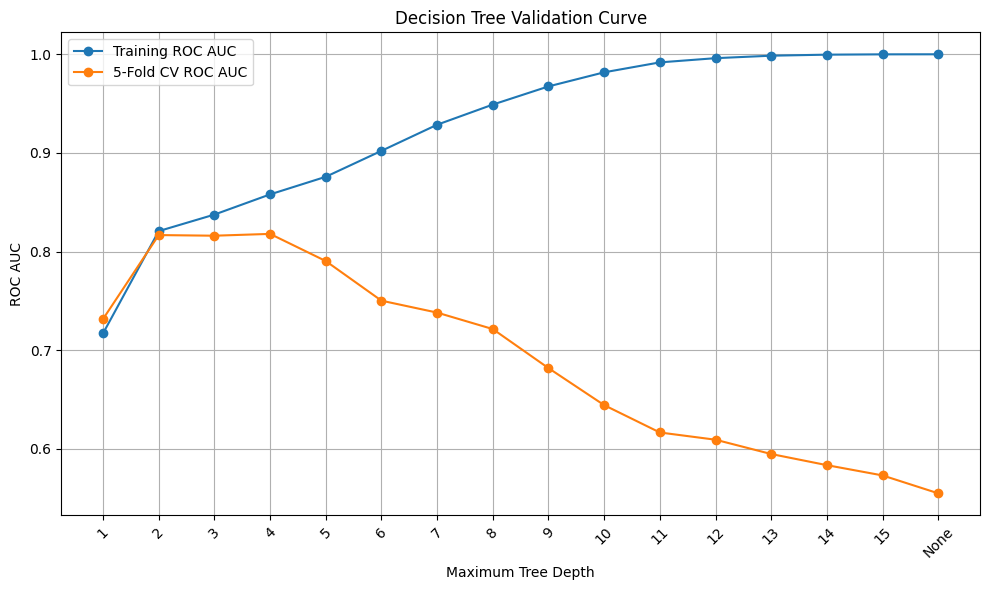

In [12]:
#Task 2.1.2
plt.figure(figsize=(10, 6))

plt.plot(
    range(len(depths)),
    train_auc_scores,
    marker="o",
    label="Training ROC AUC"
)

plt.plot(
    range(len(depths)),
    cv_auc_scores,
    marker="o",
    label="5-Fold CV ROC AUC"
)

depth_labels = [str(d) for d in depths]
plt.xticks(range(len(depths)), depth_labels, rotation=45)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree Validation Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
#The validation curve shows how Decision Tree complexity affects model performance. Underfitting occurs when both training and cross-validation 
#ROC AUC are relatively low. Overfitting is indicated when training ROC AUC is high but cross-validation ROC AUC is considerably lower. 
#The best depth is the one with the highest cross-validation ROC AUC, as printed by the code.

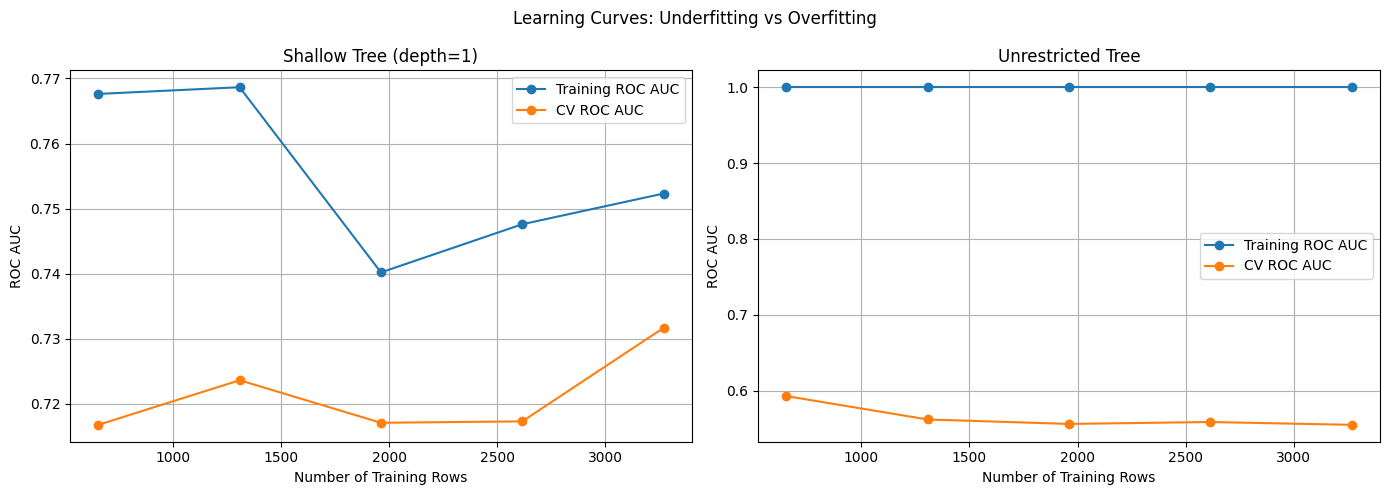


 Shallow Tree (depth=1)


,Training Rows,Mean Training ROC AUC,Mean CV ROC AUC
0,653,0.7676,0.7168
1,1307,0.7687,0.7236
2,1961,0.7402,0.7171
3,2615,0.7476,0.7173
4,3269,0.7523,0.7317



 Unrestricted Tree


,Training Rows,Mean Training ROC AUC,Mean CV ROC AUC
0,653,1.0,0.5929
1,1307,1.0,0.5620
2,1961,1.0,0.5562
3,2615,1.0,0.5587
4,3269,1.0,0.5550


In [13]:
#Task 2.2.1
models = {
    "Shallow Tree (depth=1)": DecisionTreeClassifier(
        max_depth=1,
        random_state=SEED
    ),
    "Unrestricted Tree": DecisionTreeClassifier(
        max_depth=None,
        random_state=SEED
    )
}
train_sizes = np.linspace(0.2, 1.0, 5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

learning_results = {}

for ax, (name, model) in zip(axes, models.items()):
    sizes, train_scores, valid_scores = learning_curve(
        model,
        X_train_imputed,
        y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )
    mean_train = train_scores.mean(axis=1)
    mean_valid = valid_scores.mean(axis=1)

    learning_results[name] = pd.DataFrame({
        "Training Rows": sizes,
        "Mean Training ROC AUC": mean_train,
        "Mean CV ROC AUC": mean_valid
    })

    ax.plot(sizes, mean_train, marker="o", label="Training ROC AUC")
    ax.plot(sizes, mean_valid, marker="o", label="CV ROC AUC")

    ax.set_title(name)
    ax.set_xlabel("Number of Training Rows")
    ax.set_ylabel("ROC AUC")
    ax.legend()
    ax.grid(True)

plt.suptitle("Learning Curves: Underfitting vs Overfitting")
plt.tight_layout()
plt.show()

for name, results in learning_results.items():
    print("\n", name)
    display(results.round(4))
#The learning curves show how training and cross-validation performance change as more training examples become available. A shallow tree 
#may underfit if both scores remain low and close together. An unrestricted tree may overfit if its training score is much higher than its 
#cross-validation score. Additional training data may reduce overfitting, but it may not solve underfitting caused by an overly simple model.

In [14]:
# Task 2.3.1
rng = np.random.default_rng(SEED)

depths = [1, 3, None]
n_bootstraps = 40

bootstrap_results = {}

for depth in depths:
    all_probabilities = []
    all_auc_scores = []

    for i in range(n_bootstraps):
        # Create a bootstrap sample of the training data
        idx = rng.choice(
            len(X_train_imputed),
            len(X_train_imputed),
            replace=True
        )

        X_bootstrap = X_train_imputed.iloc[idx]
        y_bootstrap = y_train.iloc[idx]

        # Train the decision tree
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + i
        )
        tree.fit(X_bootstrap, y_bootstrap)

        # Predict stroke probabilities for test patients
        probabilities = tree.predict_proba(X_test_imputed)

        if 1 in tree.classes_:
            stroke_index = list(tree.classes_).index(1)
            stroke_probabilities = probabilities[:, stroke_index]
        else:
            stroke_probabilities = np.zeros(len(X_test_imputed))

        all_probabilities.append(stroke_probabilities)

        # Calculate ROC AUC for this tree
        all_auc_scores.append(
            roc_auc_score(y_test, stroke_probabilities)
        )

    bootstrap_results[depth] = {
        "probabilities": np.array(all_probabilities),
        "auc_scores": all_auc_scores
    }

print("Bootstrap predictions collected for all three depths.")

for depth in depths:
    print(
        f"Depth {depth}:",
        bootstrap_results[depth]["probabilities"].shape
    )

Bootstrap predictions collected for all three depths.
Depth 1: (40, 1022)
Depth 3: (40, 1022)
Depth None: (40, 1022)


In [15]:
# Task 2.3.2

variance_results = []

for depth in depths:
    probs = bootstrap_results[depth]["probabilities"]
    individual_auc = bootstrap_results[depth]["auc_scores"]

    mean_variance = probs.var(axis=0).mean()

    averaged_probabilities = probs.mean(axis=0)

    averaged_auc = roc_auc_score(
        y_test,
        averaged_probabilities
    )

    mean_individual_auc = np.mean(individual_auc)

    variance_results.append({
        "Max Depth": str(depth),
        "Mean Prediction Variance": mean_variance,
        "Mean Individual Tree ROC AUC": mean_individual_auc,
        "Averaged Prediction ROC AUC": averaged_auc
    })

print("Variance and ROC AUC calculations completed.")

Variance and ROC AUC calculations completed.


In [16]:
# Task 2.3.3

variance_table = pd.DataFrame(variance_results)
display(variance_table.round(4))
#General interpretation: This cell displays the results for depths 1, 3, and None in one table. Lower prediction variance indicates more 
#stable predictions. Comparing the two ROC AUC columns shows whether averaging the 40 trees improves performance compared with the average 
#performance of individual trees.

,Max Depth,Mean Prediction Variance,Mean Individual Tree ROC AUC,Averaged Prediction ROC AUC
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7963,0.8339
2,None,0.0422,0.5526,0.7682


# QUESTIONS

(a)From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote 
train and CV AUC for one depth in each zone.

Answer: Depth 1 underfits: train AUC 0.7171 and CV AUC 0.7317 are both low. Depths 2–4 are the good zone: depth 4 has train 0.8580 and CV 0.8180, the best CV score. Depths 5 and above overfit: depth 10 has train 0.9817 but CV 0.6444, and depth None has train 1.0000 but CV 0.5550. I would choose depth 4 for the highest CV AUC. Depths 2 and 3 are almost identical (0.8168 and 0.8161) and simpler, so they are also good choices.
    
(b)From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix 
either one?

Answer: High bias occurs when training and validation performance are both low and close together, indicating that the model is too simple to learn the patterns in the data. High variance occurs when training performance is high but validation performance is considerably lower, indicating overfitting.

Adding more training data may reduce high variance by helping the model generalize better. However, it may not fix high bias; a more complex model may be required. The learning curves for the shallow and unrestricted trees help identify which situation applies to each model.Depth 1 had train ≈0.75 and CV ≈0.72–0.73 (high bias). Depth None had train 1.0 but CV ≈0.55 (high variance).

    
(c) From the variance table: how does variance change with depth? What happens to the AUC of the averaged 
prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

Answer: According to my variance table, prediction variance increases with tree depth. It is 0.0017 for depth 3 and 0.0422 for unrestricted trees (max_depth=None). This indicates that unrestricted trees are more sensitive to changes in the training data.

For depth 1, the averaged prediction ROC AUC is 0.8132, compared with a mean individual-tree ROC AUC of 0.7623. For depth 3, the averaged AUC is 0.8339, compared with 0.7963 for individual trees. For unrestricted trees, the averaged AUC is 0.7682, compared with 0.5526 for individual trees.

Therefore, averaging improves ROC AUC for all three depths in this experiment. This is related to Random Forest, which combines predictions from multiple decision trees to reduce prediction instability and often improve generalization.

    
(d)In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

Answer: The bias–variance trade-off is the balance between a model being too simple and being too sensitive to changes in its training data.
- Depth 1: A simple model that is more likely to have high bias and underfit. Its prediction variance is low.
- Depth 3: A moderately complex model that offers a better balance. In my results, it has the highest averaged prediction ROC AUC of 0.8339.
- Depth None: A highly flexible model that can fit complex patterns but is more likely to overfit. It has the highest prediction variance, 0.0422, and a lower averaged ROC AUC of 0.7682 than depth 3.
Overall, depth 3 performs best among these three depths based on the averaged prediction ROC AUC, while depth 4 is the best choice according to the validation curve in Task 2.1. These results can differ because the two experiments evaluate models differently.

# Part 3 — ROC, AUC, Precision-Recall and Thresholds

In [17]:
#Task 3.1.1

lr_model = LogisticRegression(max_iter=1000, random_state=SEED)
lr_model.fit(X_train_scaled, y_train)

dt_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=SEED
)
dt_model.fit(X_train_imputed, y_train)

rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)
rf_model.fit(X_train_imputed, y_train)

y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
y_prob_dt = dt_model.predict_proba(X_test_imputed)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test_imputed)[:, 1]

print("All three models trained successfully.")

All three models trained successfully.


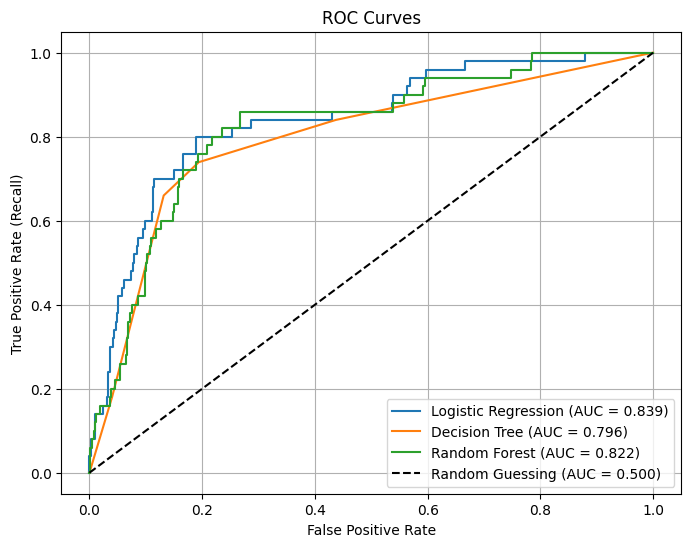

In [18]:
#Task 3.1.2

from sklearn.metrics import roc_curve, roc_auc_score

models = {
    "Logistic Regression": y_prob_lr,
    "Decision Tree": y_prob_dt,
    "Random Forest": y_prob_rf
}

plt.figure(figsize=(8, 6))

for name, probabilities in models.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Guessing (AUC = 0.500)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves")
plt.legend()
plt.grid(True)
plt.show()
#ROC curves compare the true positive rate with the false positive rate across different thresholds. A higher AUC generally indicates 
#better ability to distinguish stroke patients from non-stroke patients.

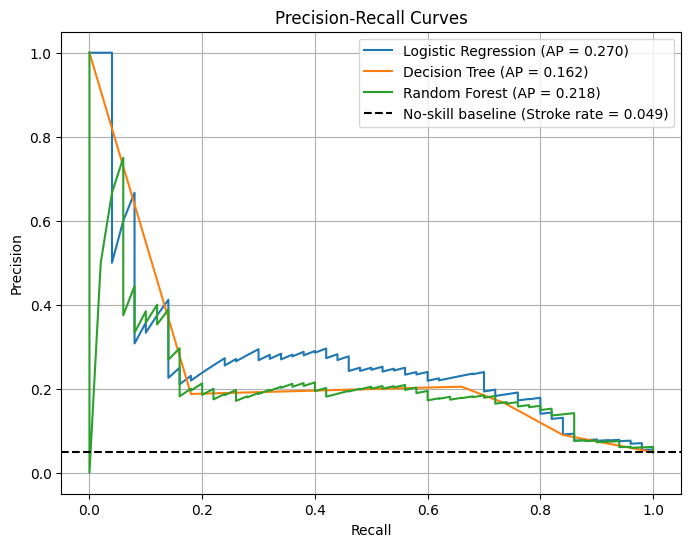

In [19]:
#Task 3.1.3

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for name, probabilities in models.items():
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap_score = average_precision_score(y_test, probabilities)

    plt.plot(
        recall, precision,
        label=f"{name} (AP = {ap_score:.3f})"
    )
stroke_rate = y_test.mean()

plt.axhline(
    y=stroke_rate,
    color="black",
    linestyle="--",
    label=f"No-skill baseline (Stroke rate = {stroke_rate:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(True)
plt.show()
#Precision–Recall curves show the trade-off between detecting stroke cases and avoiding false alarms. The horizontal no-skill line 
#represents the stroke rate in the test set. Average Precision (AP) summarizes the precision–recall performance.

In [20]:
#Task 3.2.1
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import recall_score
from sklearn.linear_model import LogisticRegression
import numpy as np

cv_threshold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

lr_threshold_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

oof_probabilities = cross_val_predict(
    lr_threshold_model,
    X_train_scaled,
    y_train,
    cv=cv_threshold,
    method="predict_proba"
)[:, 1]

thresholds = np.sort(np.unique(oof_probabilities))
valid_thresholds = []

for threshold in thresholds:
    predictions = (oof_probabilities >= threshold).astype(int)
    recall = recall_score(y_train, predictions, zero_division=0)

    if recall >= 0.80:
        valid_thresholds.append(threshold)

chosen_threshold = max(valid_thresholds) if valid_thresholds else 0.0

selected_predictions = (oof_probabilities >= chosen_threshold).astype(int)

print("Chosen threshold:", round(chosen_threshold, 4))
print(
    "Training out-of-fold recall:",
    round(recall_score(y_train, selected_predictions), 4)
)

Chosen threshold: 0.0507
Training out-of-fold recall: 0.804


In [21]:
#Task 3.2.2
from sklearn.metrics import (
    recall_score,
    precision_score,
    confusion_matrix
)

test_predictions = (y_prob_lr >= chosen_threshold).astype(int)

test_recall = recall_score(
    y_test, test_predictions, zero_division=0
)

test_precision = precision_score(
    y_test, test_predictions, zero_division=0
)

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

patients_flagged = int(test_predictions.sum())

false_alarms = int(fp)

print("Chosen threshold:", round(chosen_threshold, 4))
print("Test Recall:", round(test_recall, 4))
print("Test Precision:", round(test_precision, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nTrue Negatives:", tn)
print("False Positives (False Alarms):", fp)
print("False Negatives (Missed Strokes):", fn)
print("True Positives:", tp)

print("\nTotal Patients Flagged:", patients_flagged)
print("False Alarms:", false_alarms)
#This cell applies the selected threshold to the test probabilities and reports recall, precision, the confusion matrix, the total patients 
#flagged, and the false alarms. Recall shows how many actual stroke cases were detected, while precision shows how many flagged patients were 
#actual stroke cases.

Chosen threshold: 0.0507
Test Recall: 0.82
Test Precision: 0.1344

Confusion Matrix:
[[708 264]
 [  9  41]]

True Negatives: 708
False Positives (False Alarms): 264
False Negatives (Missed Strokes): 9
True Positives: 41

Total Patients Flagged: 305
False Alarms: 264


# QUESTIONS

(a)In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is much higher than 0.5. How can 
both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

Answer: ROC AUC measures how well a model ranks stroke patients above non-stroke patients across different thresholds. Recall at the default threshold of 0.5 measures the proportion of actual stroke cases detected at that particular cutoff. Therefore, a model can have a good ROC AUC but low recall at 0.5, especially when stroke cases are rare. In my results, ROC AUC is 0.839 but recall at 0.5 is only 0.02, while the threshold 0.0507 gives recall 0.82.


(b)Which metric curve is more informative for this data - ROC or Precision-Recall - and why? Use the no-skill line 
in your answer.

Answer: The Precision–Recall curve is particularly informative because stroke cases are the minority class. Its no-skill baseline equals the stroke rate, making it easier to assess whether the model identifies stroke cases better than a baseline. ROC curves are also useful for measuring overall discrimination.


(c) At your chosen threshold, what is the price the hospital pays for the higher recall? Is it acceptable? Argue 
both sides in 3-4 lines.

Answer: A lower threshold can detect more stroke cases, but it usually increases false alarms and decreases precision. This may require more hospital resources for additional examinations. However, in a screening setting, accepting more false alarms may be reasonable if it helps reduce missed strokes. The final decision should depend on clinical priorities and the costs of false positives and false negatives.In my case, 305 patients were flagged, 264 of them false alarms, with precision 0.134.

# Part 4 — Undersampling, Oversampling and SMOTE

In [22]:
# Task 4.1.1
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

X_train_lr = X_train_scaled
X_train_rf = X_train_imputed

model_data = {
    "Logistic Regression": (X_train_lr, X_test_scaled),
    "Random Forest": (X_train_rf, X_test_imputed)
}

methods = [
    "No Resampling",
    "Class Weight Balanced",
    "Random Undersampling",
    "Random Oversampling",
    "SMOTE"
]

results = []

for model_name, (X_train_base, X_test_base) in model_data.items():

    for method in methods:

        X_res = X_train_base
        y_res = y_train
        class_weight = None

        if method == "Class Weight Balanced":
            class_weight = "balanced"

        elif method == "Random Undersampling":
            X_res, y_res = RandomUnderSampler(
                random_state=SEED
            ).fit_resample(X_train_base, y_train)

        elif method == "Random Oversampling":
            X_res, y_res = RandomOverSampler(
                random_state=SEED
            ).fit_resample(X_train_base, y_train)

        elif method == "SMOTE":
            X_res, y_res = SMOTE(
                random_state=SEED
            ).fit_resample(X_train_base, y_train)

        if model_name == "Logistic Regression":
            model = LogisticRegression(
                max_iter=1000,
                random_state=SEED,
                class_weight=class_weight
            )
        else:
            model = RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                random_state=SEED,
                class_weight=class_weight
            )

        model.fit(X_res, y_res)

        y_pred = model.predict(X_test_base)
        y_prob = model.predict_proba(X_test_base)[:, 1]

        results.append({
            "Model": model_name,
            "Method": method,
            "Training Rows": len(y_res),
            "Training Strokes": int(np.asarray(y_res).sum()),
            "Precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "ROC AUC": roc_auc_score(y_test, y_prob),
            "PR AUC": average_precision_score(y_test, y_prob)
        })

print("All 10 models trained and evaluated.")

All 10 models trained and evaluated.


In [23]:
# Task 4.1.2
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["Model", "Method"]
).reset_index(drop=True)

results_df.round(4)
#The table compares the training-set size and stroke count alongside Precision, Recall, F1, ROC AUC and PR AUC. ROC AUC measures ranking 
#ability across thresholds, while PR AUC summarizes the precision-recall trade-off and is particularly useful for imbalanced data.

,Model,Method,Training Rows,Training Strokes,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,Class Weight Balanced,4087,199,0.1347,0.80,0.2305,0.8396,0.2596
1,Logistic Regression,No Resampling,4087,199,1.0000,0.02,0.0392,0.8393,0.2696
2,Logistic Regression,Random Oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2591
3,Logistic Regression,Random Undersampling,398,199,0.1246,0.82,0.2164,0.8350,0.2333
4,Logistic Regression,SMOTE,7776,3888,0.1347,0.80,0.2305,0.8407,0.2957
5,Random Forest,Class Weight Balanced,4087,199,0.1667,0.20,0.1818,0.8061,0.2045
6,Random Forest,No Resampling,4087,199,0.0000,0.00,0.0000,0.8215,0.2183
7,Random Forest,Random Oversampling,7776,3888,0.1412,0.24,0.1778,0.8023,0.1837
8,Random Forest,Random Undersampling,398,199,0.1032,0.84,0.1838,0.8132,0.1972
9,Random Forest,SMOTE,7776,3888,0.6667,0.04,0.0755,0.8046,0.2424


In [24]:
# Task 4.2.1

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

X_all = np.vstack([
    np.asarray(X_train_imputed),
    np.asarray(X_test_imputed)
])

y_all = np.concatenate([
    np.asarray(y_train),
    np.asarray(y_test)
])

X_smote_all, y_smote_all = SMOTE(
    random_state=SEED
).fit_resample(X_all, y_all)

X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = (
    train_test_split(
        X_smote_all,
        y_smote_all,
        test_size=0.20,
        random_state=SEED,
        stratify=y_smote_all
    )
)

rf_wrong = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

rf_wrong.fit(X_train_wrong, y_train_wrong)

y_pred_wrong = rf_wrong.predict(X_test_wrong)
y_prob_wrong = rf_wrong.predict_proba(X_test_wrong)[:, 1]

wrong_metrics = {
    "Precision": precision_score(
        y_test_wrong, y_pred_wrong, zero_division=0
    ),
    "Recall": recall_score(
        y_test_wrong, y_pred_wrong, zero_division=0
    ),
    "F1": f1_score(
        y_test_wrong, y_pred_wrong, zero_division=0
    ),
    "ROC AUC": roc_auc_score(y_test_wrong, y_prob_wrong),
    "PR AUC": average_precision_score(y_test_wrong, y_prob_wrong)
}

print("Wrong-order SMOTE evaluation:")
for metric, value in wrong_metrics.items():
    print(f"{metric}: {value:.4f}")

Wrong-order SMOTE evaluation:
Precision: 0.9957
Recall: 0.9578
F1: 0.9764
ROC AUC: 0.9948
PR AUC: 0.9958


In [25]:
# Task 4.2.2

correct_smote = results_df[
    (results_df["Model"] == "Random Forest") &
    (results_df["Method"] == "SMOTE")
].iloc[0]

comparison_df = pd.DataFrame([
    {
        "Evaluation": "Correct SMOTE (split first)",
        "Precision": correct_smote["Precision"],
        "Recall": correct_smote["Recall"],
        "F1": correct_smote["F1"],
        "ROC AUC": correct_smote["ROC AUC"],
        "PR AUC": correct_smote["PR AUC"]
    },
    {
        "Evaluation": "Wrong SMOTE (resample first)",
        "Precision": wrong_metrics["Precision"],
        "Recall": wrong_metrics["Recall"],
        "F1": wrong_metrics["F1"],
        "ROC AUC": wrong_metrics["ROC AUC"],
        "PR AUC": wrong_metrics["PR AUC"]
    }
])

comparison_df.round(4)
#This table compares the proper evaluation—SMOTE applied only after splitting—with the deliberately incorrect evaluation. The wrong-order 
#scores may look better, but the two test sets differ, and the second evaluation has leakage risk. Higher scores do not prove that the model 
#will perform better on new patients.

,Evaluation,Precision,Recall,F1,ROC AUC,PR AUC
0,Correct SMOTE (split first),0.6667,0.0400,0.0755,0.8046,0.2424
1,Wrong SMOTE (resample first),0.9957,0.9578,0.9764,0.9948,0.9958


# QUESTIONS

(a)For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision 
and ROC AUC across the methods and explain why.

Answer: Resampling significantly affected Precision and Recall, while ROC AUC and PR AUC changed only slightly.
- Recall: Without resampling, recall was only 0.02 (2%). With class weighting, oversampling and SMOTE, it increased to 0.80 (80%). Undersampling achieved the highest recall of 0.82 (82%).
- Precision: Without resampling, precision was 1.00 (100%), but this was because the model detected very few stroke cases. After balancing, precision decreased to approximately 0.12–0.13 because more patients were classified as potential stroke cases.
- ROC AUC: It remained relatively stable, between 0.8350 and 0.8407, showing that the model's ability to rank positive cases above negative cases did not change much.
- PR AUC: It also remained relatively stable, between 0.2591 and 0.2957. SMOTE achieved the highest PR AUC of 0.2957.
Overall, resampling helped Logistic Regression detect many more stroke cases, but this came at the cost of lower precision. The test data remained unchanged; the training data and learning process changed.
    
(b)Did Random Forest react to the methods in the same way as Logistic Regression? Describe one clear 
difference and give one possible reason.

Answer: No, Random Forest reacted differently.

For Logistic Regression, all four balancing approaches increased recall to around 80–82%. However, Random Forest's recall varied considerably:
- Class weighting: Recall was only 0.20 (20%).
- Random oversampling: Recall was 0.24 (24%).
- Random undersampling: Recall increased to 0.84 (84%), the highest among the Random Forest methods.
- SMOTE: Recall was only 0.04 (4%).
One possible reason is that Logistic Regression learns a linear decision boundary, while Random Forest combines multiple decision trees to learn nonlinear patterns. Different balancing methods can affect these models differently. Random undersampling may have helped Random Forest learn the minority class more effectively in this experiment.

    
(c) Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why 
can they not be trusted? Explain what leaks from where.

Answer: The wrong-order SMOTE result is dramatically better than the correct result.
| Metric | Correct SMOTE | Wrong-order SMOTE |
|---|---:|---:|
| Precision | 0.6667 | 0.9957 |
| Recall | 0.0400 | 0.9578 |
| F1 | 0.0755 | 0.9764 |
| ROC AUC | 0.8046 | 0.9948 |
| PR AUC | 0.2424 | 0.9958 |
The wrong-order method produces extremely high scores because SMOTE is applied to the entire dataset before splitting it into training and test sets. Synthetic samples can be generated using information from observations that later appear in the test set. Related synthetic samples may then appear in both sets, making the test data less independent.
This is a form of data leakage, which can make the model appear much better than it really is. Therefore, the wrong-order metrics cannot be trusted as a fair estimate of performance on unseen patients.
The correct procedure is to split the original data first, apply SMOTE only to the training set, and evaluate on the untouched test set.The wrong-order test set also contains synthetic patients interpolated between real strokes, and many of those real stroke patients are also in the training set. The test set is balanced and partly artificial, so the model is being tested on near-copies of its training data.

    
(d)If you had to pick one rebalancing approach for this hospital, which would you pick and why? Consider 
simplicity and the cost of each choice.

Answer: I would initially choose class_weight='balanced' for Logistic Regression because it is simple to implement, does not discard majority-class observations, and does not create synthetic patient records.
In our results, class-weighted Logistic Regression achieved 80% recall and a ROC AUC of 0.8396. This is a reasonable starting point for a hospital screening model, although its precision of 0.1347 means many flagged patients were not stroke cases.
If maximizing stroke detection is the main priority, Random Forest with random undersampling achieved 84% recall. However, undersampling discards many non-stroke training observations, potentially losing useful information.
The hospital should compare the cost of missed stroke cases against the cost of false alarms, select an appropriate decision threshold, and validate the model carefully before clinical use. No method should be selected solely because it produces the highest score.

# Part 5 — Noisy Data

In [26]:
# Task 5.1.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def flip_labels(y, fraction, random_state):
    y_noisy = np.asarray(y).copy()
    rng = np.random.default_rng(random_state)

    n_flip = int(round(len(y_noisy) * fraction))
    flip_indices = rng.choice(
        len(y_noisy), size=n_flip, replace=False
    )

    y_noisy[flip_indices] = 1 - y_noisy[flip_indices]

    return y_noisy
test_noisy_labels = flip_labels(y_train, 0.05, SEED)

print("Original labels:", len(y_train))
print("Labels flipped:", int(np.sum(test_noisy_labels != np.asarray(y_train))))

Original labels: 4087
Labels flipped: 204


In [27]:
# Task 5.1.2
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

noise_fractions = [0, 0.05, 0.10, 0.20]
label_noise_results = []
for fraction in noise_fractions:
    repeats = 1 if fraction == 0 else 5

    for repeat in range(repeats):
        noisy_seed = SEED + repeat
        y_noisy = flip_labels(
            y_train, fraction, random_state=noisy_seed
        )

        models_to_train = {
            "Logistic Regression": (
                LogisticRegression(max_iter=1000, random_state=SEED),
                X_train_scaled,
                X_test_scaled
            ),
            "Decision Tree (Depth 3)": (
                DecisionTreeClassifier(max_depth=3, random_state=SEED),
                X_train_imputed,
                X_test_imputed
            ),
            "Decision Tree (Unlimited)": (
                DecisionTreeClassifier(random_state=SEED),
                X_train_imputed,
                X_test_imputed
            ),
            "Random Forest": (
                RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED
                ),
                X_train_imputed,
                X_test_imputed
            )
        }

        for model_name, (model, X_tr, X_te) in models_to_train.items():

            model.fit(X_tr, y_noisy)
            probabilities = model.predict_proba(X_te)[:, 1]

            label_noise_results.append({
                "Noise Fraction": fraction,
                "Repeat": repeat + 1,
                "Model": model_name,
                "ROC AUC": roc_auc_score(y_test, probabilities)
            })

label_noise_df = pd.DataFrame(label_noise_results)

print("Label-noise experiments completed.")

Label-noise experiments completed.


Model,Decision Tree (Depth 3),Decision Tree (Unlimited),Logistic Regression,Random Forest
Noise Fraction,,,,
0.00,0.7956,0.5722,0.8393,0.8215
0.05,0.8014,0.5550,0.8239,0.7896
0.10,0.8029,0.5310,0.8132,0.7459
0.20,0.7263,0.5060,0.7745,0.6699


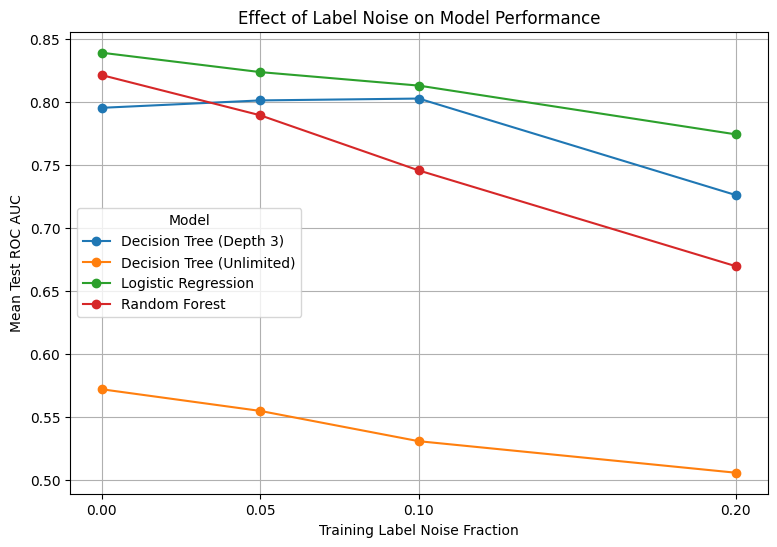

In [28]:
# Task 5.1.3

label_noise_table = label_noise_df.pivot_table(
    index="Noise Fraction",
    columns="Model",
    values="ROC AUC",
    aggfunc="mean"
)

display(label_noise_table.round(4))

label_noise_table.plot(
    marker="o",
    figsize=(9, 6)
)

plt.xlabel("Training Label Noise Fraction")
plt.ylabel("Mean Test ROC AUC")
plt.title("Effect of Label Noise on Model Performance")
plt.xticks(noise_fractions)
plt.grid(True)
plt.legend(title="Model")
plt.show()

In [29]:
# Task 5.2.1
from sklearn.preprocessing import StandardScaler
feature_columns = [
    "age",
    "avg_glucose_level",
    "bmi"
]
missing_columns = [
    col for col in feature_columns
    if col not in X_train_imputed.columns
]

if missing_columns:
    raise ValueError(f"Missing feature columns: {missing_columns}")

def add_feature_noise(X, level, random_state):
    X_noisy = X.copy()
    rng = np.random.default_rng(random_state)

    for col in feature_columns:
        column_std = X[col].std()
        noise = rng.normal(
            loc=0,
            scale=column_std * level,
            size=len(X)
        )
        X_noisy[col] = X_noisy[col] + noise

    return X_noisy

X_feature_test = add_feature_noise(
    X_train_imputed, level=0.5, random_state=SEED
)

print("Original training shape:", X_train_imputed.shape)
print("Noisy training shape:", X_feature_test.shape)

feature_noise_levels = [0, 0.5, 1, 2]
feature_noise_results = []

for level in feature_noise_levels:

    for repeat in range(5):

        noisy_seed = SEED + repeat

        # Add noise to training features only
        X_train_noisy = add_feature_noise(
            X_train_imputed,
            level=level,
            random_state=noisy_seed
        )

        # Fit scaler on this noisy training set only
        scaler_noisy = StandardScaler()
        X_train_noisy_scaled = scaler_noisy.fit_transform(
            X_train_noisy
        )
        X_test_noisy_scaled = scaler_noisy.transform(
            X_test_imputed
        )

        models_to_train = {
            "Logistic Regression": (
                LogisticRegression(max_iter=1000, random_state=SEED),
                X_train_noisy_scaled,
                X_test_noisy_scaled
            ),
            "Decision Tree (Depth 3)": (
                DecisionTreeClassifier(max_depth=3, random_state=SEED),
                X_train_noisy,
                X_test_imputed
            ),
            "Decision Tree (Unlimited)": (
                DecisionTreeClassifier(random_state=SEED),
                X_train_noisy,
                X_test_imputed
            ),
            "Random Forest": (
                RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED
                ),
                X_train_noisy,
                X_test_imputed
            )
        }

        for model_name, (model, X_tr, X_te) in models_to_train.items():

            model.fit(X_tr, y_train)
            probabilities = model.predict_proba(X_te)[:, 1]

            feature_noise_results.append({
                "Noise Level": level,
                "Repeat": repeat + 1,
                "Model": model_name,
                "ROC AUC": roc_auc_score(y_test, probabilities)
            })

feature_noise_df = pd.DataFrame(feature_noise_results)

print("Feature-noise experiments completed.")

Original training shape: (4087, 20)
Noisy training shape: (4087, 20)
Feature-noise experiments completed.


Model,Decision Tree (Depth 3),Decision Tree (Unlimited),Logistic Regression,Random Forest
Noise Level,,,,
0.0,0.7956,0.5722,0.8393,0.8215
0.5,0.7995,0.5751,0.8337,0.8082
1.0,0.7610,0.5271,0.8098,0.7782
2.0,0.6942,0.5283,0.7690,0.7352


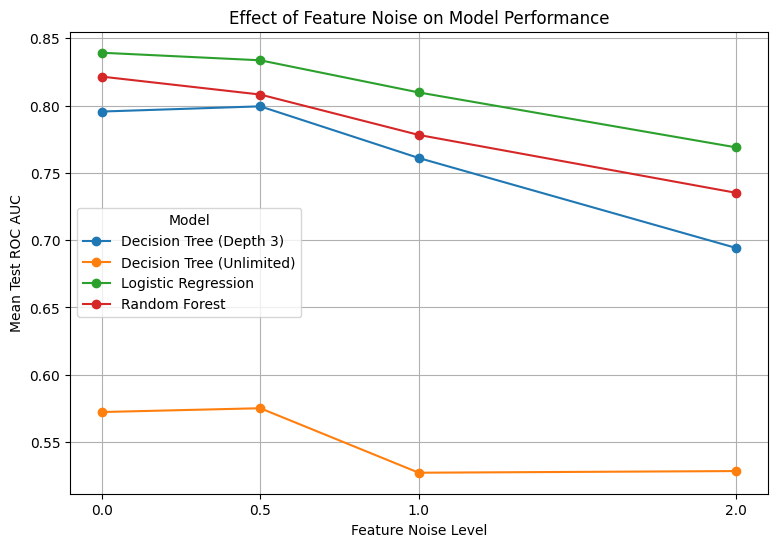

In [30]:
# Task 5.2.2
feature_noise_table = feature_noise_df.pivot_table(
    index="Noise Level",
    columns="Model",
    values="ROC AUC",
    aggfunc="mean"
)

display(feature_noise_table.round(4))

feature_noise_table.plot(
    marker="o",
    figsize=(9, 6)
)

plt.xlabel("Feature Noise Level")
plt.ylabel("Mean Test ROC AUC")
plt.title("Effect of Feature Noise on Model Performance")
plt.xticks(feature_noise_levels)
plt.grid(True)
plt.legend(title="Model")
plt.show()

In [31]:
# Task 5.3.1
from imblearn.over_sampling import SMOTE
from sklearn.metrics import average_precision_score

smote_noise_results = []

for repeat in range(3):

    # Flip 10% of training labels using a different random draw
    y_noisy = flip_labels(
        y_train,
        fraction=0.10,
        random_state=SEED + 100 + repeat
    )

    model_inputs = {
        "Logistic Regression": (
            X_train_scaled,
            X_test_scaled
        ),
        "Random Forest": (
            X_train_imputed,
            X_test_imputed
        )
    }

    for model_name, (X_tr, X_te) in model_inputs.items():

        for method in ["Without SMOTE", "With SMOTE"]:

            X_fit = X_tr
            y_fit = y_noisy

            if method == "With SMOTE":
                X_fit, y_fit = SMOTE(
                    random_state=SEED + repeat
                ).fit_resample(X_tr, y_noisy)

            if model_name == "Logistic Regression":
                model = LogisticRegression(
                    max_iter=1000,
                    random_state=SEED
                )
            else:
                model = RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED
                )

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(X_te)[:, 1]

            # Evaluate against the original, clean test labels
            smote_noise_results.append({
                "Repeat": repeat + 1,
                "Model": model_name,
                "Method": method,
                "ROC AUC": roc_auc_score(y_test, probabilities),
                "PR AUC": average_precision_score(y_test, probabilities)
            })

smote_noise_df = pd.DataFrame(smote_noise_results)

print("Results for all three random draws:")
display(smote_noise_df.round(4))

print("Average results across the three draws:")
smote_noise_summary = smote_noise_df.groupby(
    ["Model", "Method"]
)[["ROC AUC", "PR AUC"]].mean()

display(smote_noise_summary.round(4))

Results for all three random draws:


,Repeat,Model,Method,ROC AUC,PR AUC
0,1,Logistic Regression,Without SMOTE,0.8014,0.2141
1,1,Logistic Regression,With SMOTE,0.7941,0.2067
2,1,Random Forest,Without SMOTE,0.7705,0.1778
3,1,Random Forest,With SMOTE,0.6944,0.1376
4,2,Logistic Regression,Without SMOTE,0.8222,0.2746
5,2,Logistic Regression,With SMOTE,0.8152,0.2577
6,2,Random Forest,Without SMOTE,0.8029,0.1871
7,2,Random Forest,With SMOTE,0.7241,0.1387
8,3,Logistic Regression,Without SMOTE,0.7953,0.2128
9,3,Logistic Regression,With SMOTE,0.7662,0.2026


Average results across the three draws:


ROC AUC  PR AUC
Model               Method                        
Logistic Regression With SMOTE      0.7918  0.2223
                    Without SMOTE   0.8063  0.2339
Random Forest       With SMOTE      0.7025  0.1432
                    Without SMOTE   0.7859  0.1942

# QUESTIONS

(a)Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level 
and explain using what you learned in Part 2.

Answer: At 20% label noise, Random Forest is the most damaged: ROC AUC falls from 0.8215 to 0.6699 (−0.1516). Logistic Regression is the most stable among the useful models, falling from 0.8393 to 0.7745 (−0.0648). The depth-3 tree falls 0.0693 (0.7956 → 0.7263). The unlimited tree falls 0.0662, but it was already near chance (0.5722 → 0.5060), so it had little left to lose. This matches Part 2: flexible models have high variance and fit whatever they are given, including wrong labels. With min_samples_leaf=5 and 200 trees, Random Forest fits the flipped labels. Flipping 20% of 4,087 labels creates about 780 fake strokes from healthy patients, against only 199 real strokes. Most of the “stroke” class then becomes noise. Logistic Regression can only draw one smooth boundary, so it cannot memorise the noise.


(b)Which hurts more here - label noise or feature noise of a comparable level? Give a short reason.

Answer: The answer depends on the model. For Logistic Regression, feature noise (level 2) hurt slightly more than label noise (20%): −0.0703 against −0.0648. The same is true for the depth-3 tree (−0.1014 against −0.0693). For Random Forest, label noise hurt much more (−0.1516 against −0.0863). Label noise changes the target itself. Because strokes are rare, flipped healthy patients outnumber the real strokes. Feature noise only blurs the inputs, and the strong signals such as age still survive. A flexible model like Random Forest is hurt most by wrong labels because it tries to fit them.

(c) What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

Answer: SMOTE reduced the average performance of both models when 10% of the training labels were flipped.
| Model | Method | ROC AUC | PR AUC |
|---|---|---:|---:|
| Logistic Regression | Without SMOTE | 0.8063 | 0.2339 |
| Logistic Regression | With SMOTE | 0.7918 | 0.2223 |
| Random Forest | Without SMOTE | 0.7859 | 0.1942 |
| Random Forest | With SMOTE | 0.7025 | 0.1432 |

For Logistic Regression, ROC AUC decreased by 0.0145 and PR AUC decreased by 0.0116. For Random Forest, ROC AUC decreased by 0.0834 and PR AUC decreased by 0.0510.

SMOTE may amplify label noise because it generates synthetic minority-class examples using nearby minority-class observations. If a mislabeled observation is treated as a minority-class example, SMOTE may generate additional synthetic samples based on that incorrect label. This can reinforce misleading patterns in the training data.

# Part 6 — Final Decision and Conclusion

In [34]:
# Task 6.1 
rows = []
for label, t in [("Default 0.5", 0.5),
                 (f"Chosen {chosen_threshold:.4f} (from train OOF)", chosen_threshold)]:
    pred = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({
        "Threshold": label,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "False Alarms": fp,
        "Missed Strokes": fn
    })

display(pd.DataFrame(rows).round(4))
#Lowering the threshold from 0.5 to 0.0507 raises recall from 0.02 to 0.82 and cuts missed strokes from 49 to 9, at the cost of 264 false alarms 
#and precision of 0.134.

,Threshold,Precision,Recall,F1,False Alarms,Missed Strokes
0,Default 0.5,1.0000,0.02,0.0392,0,49
1,Chosen 0.0507 (from train OOF),0.1344,0.82,0.2310,264,9


Executive Summary:

I chose Logistic Regression (scaled data, no resampling) with a decision threshold of 0.0507. I picked it using out-of-fold probabilities on the training set only, as the highest threshold giving at least 80% recall. On the untouched test set it reached recall 0.82 (41 of 50 strokes caught) and precision 0.134. The default threshold of 0.5 caught only 1 of 50 (recall 0.02). The price is 264 false alarms, so 305 patients (about 30% of the test set) are flagged and only about 1 in 7 flagged patients actually has a stroke. Only 9 strokes are missed, versus 49 at 0.5. I avoided leakage by fitting the imputer and scaler on the training data only, learning the threshold on training data only, and never touching the test set. One limitation is that the test set has only 50 stroke patients, so a few patients change recall by several points. The threshold also depends on the 80% recall target, which should be set by clinicians.

# Final Reflection

(a) What was the most surprising result in this lab?

Answer: The most surprising result was that Logistic Regression had a ROC AUC of 0.839 but caught only 1 of 50 strokes at the default 0.5 threshold. Simply lowering the threshold to 0.0507 raised recall to 0.82 without retraining. Also, SMOTE on all the data before splitting made Random Forest look nearly perfect (ROC AUC 0.995), while the correct result was 0.805.

(b) If you had one more hour, what would you try next?

Answer: I would test threshold choice with repeated cross-validation and report a confidence interval on recall, since the test set has only 50 strokes. I would also try class_weight='balanced' with calibrated probabilities and compare the cost of false alarms against missed strokes.